# 03B: Merge in celltypes from the Seurat obj

In [1]:
import spatialdata as sd
import spatialdata_plot
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")
halfbrain_path = data_dir / Path("halfbrain_sdata.zarr")
quarterbrain_path = data_dir / Path("quarterbrain_sdata.zarr")

## Get FOV coordinates for both datasets

In [3]:
fovs_halfbrain_path = proj_dir / Path("data/raw/HalfBrain_20230406_205644_S1/Run1000_S1_Half_fov_positions_file.csv")
fovs_quarterbrain_path = proj_dir / Path("data/raw/QuarterBrain_resegmented/Run5642_S3_Quarter_fov_positions_file.csv")

fovs_halfbrain = pd.read_csv(fovs_halfbrain_path)
fovs_quarterbrain = pd.read_csv(fovs_quarterbrain_path)

fovs_quarterbrain

,fov,x_global_px,y_global_px
0,1,171400.000000,11341.666667
1,2,171400.000000,7075.000000
2,3,171400.000000,2808.333333
3,4,171400.000000,-1458.333333
4,5,171400.000000,-5725.000000
...,...,...,...
61,62,128733.333333,7075.000000
62,63,128733.333333,2808.333333
63,64,128733.333333,-1458.333333
64,65,128733.333333,-5725.000000


## Load celltypes from Seurat

In [4]:
seurat_obj_path = proj_dir / Path("data/seurat_celltypes.csv")
seurat_obj = pd.read_csv(seurat_obj_path)
celltypes_quarterbrain = seurat_obj.query("tissue == 'Quarter'")
celltypes_halfbrain = seurat_obj.query("tissue == 'Half'")
celltypes_halfbrain

,cell_barcode,cluster,cluster_long,tissue,run_tissue,fov,x_fov_px,y_fov_px
24117,c_2_100_1,VEC,Vascular_endothelial_cells,Half,Run1000_S1_Half,100,1369,16
24118,c_2_100_100,MOL,Mature_oligodendrocytes,Half,Run1000_S1_Half,100,4103,1663
24119,c_2_100_101,INH_HB_TH,Inhibitory_neurons_Habenula_Thalamus,Half,Run1000_S1_Half,100,3264,1696
24120,c_2_100_103,EXC_DM,Excitatory_neurons_Di/mesencephalon,Half,Run1000_S1_Half,100,110,1710
24121,c_2_100_104,VSMC,Vascular_smooth_muscle_cells,Half,Run1000_S1_Half,100,616,1702
...,...,...,...,...,...,...,...,...
86911,c_2_99_756,GN,Granule_neurons,Half,Run1000_S1_Half,99,3855,3623
86912,c_2_9_153,EXC_AMY,Excitatory_neurons_Amygdala,Half,Run1000_S1_Half,9,2203,2893
86913,c_2_9_168,EXC_L1_PIR,Excitatory_neurons_Layer1_Piriform,Half,Run1000_S1_Half,9,3046,3182
86914,c_2_9_210,AC_CTX_HIP,Astrocytes_Cortex_Hippocampus,Half,Run1000_S1_Half,9,1815,3708


## Load sdata and merge them in

### Quarterbrain

In [5]:
quarterbrain_sdata =  sd.read_zarr(quarterbrain_path)
quarterbrain_sdata

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kw

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/quarterbrain_sdata.zarr
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 25589, 46923), (5, 12794, 23461), (5, 6397, 11730), (5, 3198, 5865), (5, 1599, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (25589, 46923), (12794, 23461), (6397, 11730), (3198, 5865), (1599, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (38996, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

In [6]:
quarterbrain_sdata.tables["gexp"].obs

,fov,cellID,global_cell_id,x_global_px,y_global_px,x_local_px,y_local_px,region
0,1,1,1,171450.000000,15597.666667,50,4256,segmentation
1,1,2,2,171745.000000,15597.666667,345,4256,segmentation
2,1,3,3,171929.000000,15597.666667,529,4256,segmentation
3,1,4,4,172254.000000,15597.666667,854,4256,segmentation
4,1,5,5,172614.000000,15597.666667,1214,4256,segmentation
...,...,...,...,...,...,...,...,...
38991,66,710,38992,129335.333333,-9886.666667,602,105,segmentation
38992,66,711,38993,132823.333333,-9913.666667,4090,78,segmentation
38993,66,712,38994,129642.333333,-9950.666667,909,41,segmentation
38994,66,713,38995,132082.333333,-9966.666667,3349,25,segmentation


In [7]:
quarterbrain_sdata.tables["gexp"].obs["cell_barcode"] = [f"c_1_{row['fov']}_{row['cellID']}" for _, row in quarterbrain_sdata.tables["gexp"].obs.iterrows()]

quarterbrain_sdata.tables["gexp"].obs.sort_values("cell_barcode")

,fov,cellID,global_cell_id,x_global_px,y_global_px,x_local_px,y_local_px,region,cell_barcode
5527,10,1,5528,167434.333333,7064.333333,301,4256,segmentation,c_1_10_1
5536,10,10,5537,170611.333333,7064.333333,3478,4256,segmentation,c_1_10_10
5626,10,100,5627,169099.333333,6136.333333,1966,3328,segmentation,c_1_10_100
5627,10,101,5628,168090.333333,6166.333333,957,3358,segmentation,c_1_10_101
5628,10,102,5629,168786.333333,6107.333333,1653,3299,segmentation,c_1_10_102
...,...,...,...,...,...,...,...,...,...
5087,9,95,5088,168803.333333,1045.666667,1670,2504,segmentation,c_1_9_95
5088,9,96,5089,169124.333333,1034.666667,1991,2493,segmentation,c_1_9_96
5089,9,97,5090,168940.333333,1004.666667,1807,2463,segmentation,c_1_9_97
5090,9,98,5091,168355.333333,989.666667,1222,2448,segmentation,c_1_9_98


In [8]:
quarterbrain_sdata.tables["gexp"].obs = quarterbrain_sdata.tables["gexp"].obs.merge(celltypes_quarterbrain, on="cell_barcode", how="left")

In [9]:
for cat_col in ["cluster", "cluster_long"]:
    quarterbrain_sdata.tables["gexp"].obs[cat_col] = pd.Categorical(quarterbrain_sdata.tables["gexp"].obs[cat_col])

quarterbrain_sdata.tables["gexp"].obs

,fov_x,cellID,global_cell_id,x_global_px,y_global_px,x_local_px,y_local_px,region,cell_barcode,cluster,cluster_long,tissue,run_tissue,fov_y,x_fov_px,y_fov_px
0,1,1,1,171450.000000,15597.666667,50,4256,segmentation,c_1_1_1,EXC_TE,Excitatory_neurons_Telencephalon,Quarter,Run5642_S3_Quarter,1.0,30.0,42.0
1,1,2,2,171745.000000,15597.666667,345,4256,segmentation,c_1_1_2,EXC_AMY,Excitatory_neurons_Amygdala,Quarter,Run5642_S3_Quarter,1.0,304.0,16.0
2,1,3,3,171929.000000,15597.666667,529,4256,segmentation,c_1_1_3,EXC_L23,Excitatory_neurons_Layer2_3,Quarter,Run5642_S3_Quarter,1.0,466.0,36.0
3,1,4,4,172254.000000,15597.666667,854,4256,segmentation,c_1_1_4,INS,Interneurons,Quarter,Run5642_S3_Quarter,1.0,834.0,58.0
4,1,5,5,172614.000000,15597.666667,1214,4256,segmentation,c_1_1_5,EXC_L23,Excitatory_neurons_Layer2_3,Quarter,Run5642_S3_Quarter,1.0,1154.0,42.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38991,66,710,38992,129335.333333,-9886.666667,602,105,segmentation,c_1_66_710,MOL,Mature_oligodendrocytes,Quarter,Run5642_S3_Quarter,66.0,651.0,4203.0
38992,66,711,38993,132823.333333,-9913.666667,4090,78,segmentation,c_1_66_711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
38993,66,712,38994,129642.333333,-9950.666667,909,41,segmentation,c_1_66_712,MFOL,Myelin_forming_oligodendrocytes,Quarter,Run5642_S3_Quarter,66.0,873.0,4235.0
38994,66,713,38995,132082.333333,-9966.666667,3349,25,segmentation,c_1_66_713,MOL,Mature_oligodendrocytes,Quarter,Run5642_S3_Quarter,66.0,3364.0,4243.0


In [10]:
num_cols = quarterbrain_sdata.tables["gexp"].obs.select_dtypes(include="number").columns
quarterbrain_sdata.tables["gexp"].obs[num_cols] = quarterbrain_sdata.tables["gexp"].obs[num_cols].fillna(99999999)

str_cols = quarterbrain_sdata.tables["gexp"].obs.select_dtypes(include="object").columns
quarterbrain_sdata.tables["gexp"].obs[str_cols] = quarterbrain_sdata.tables["gexp"].obs[str_cols].fillna("")

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:798: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


CPU times: user 3min 7s, sys: 11 s, total: 3min 18s
Wall time: 42.1 s


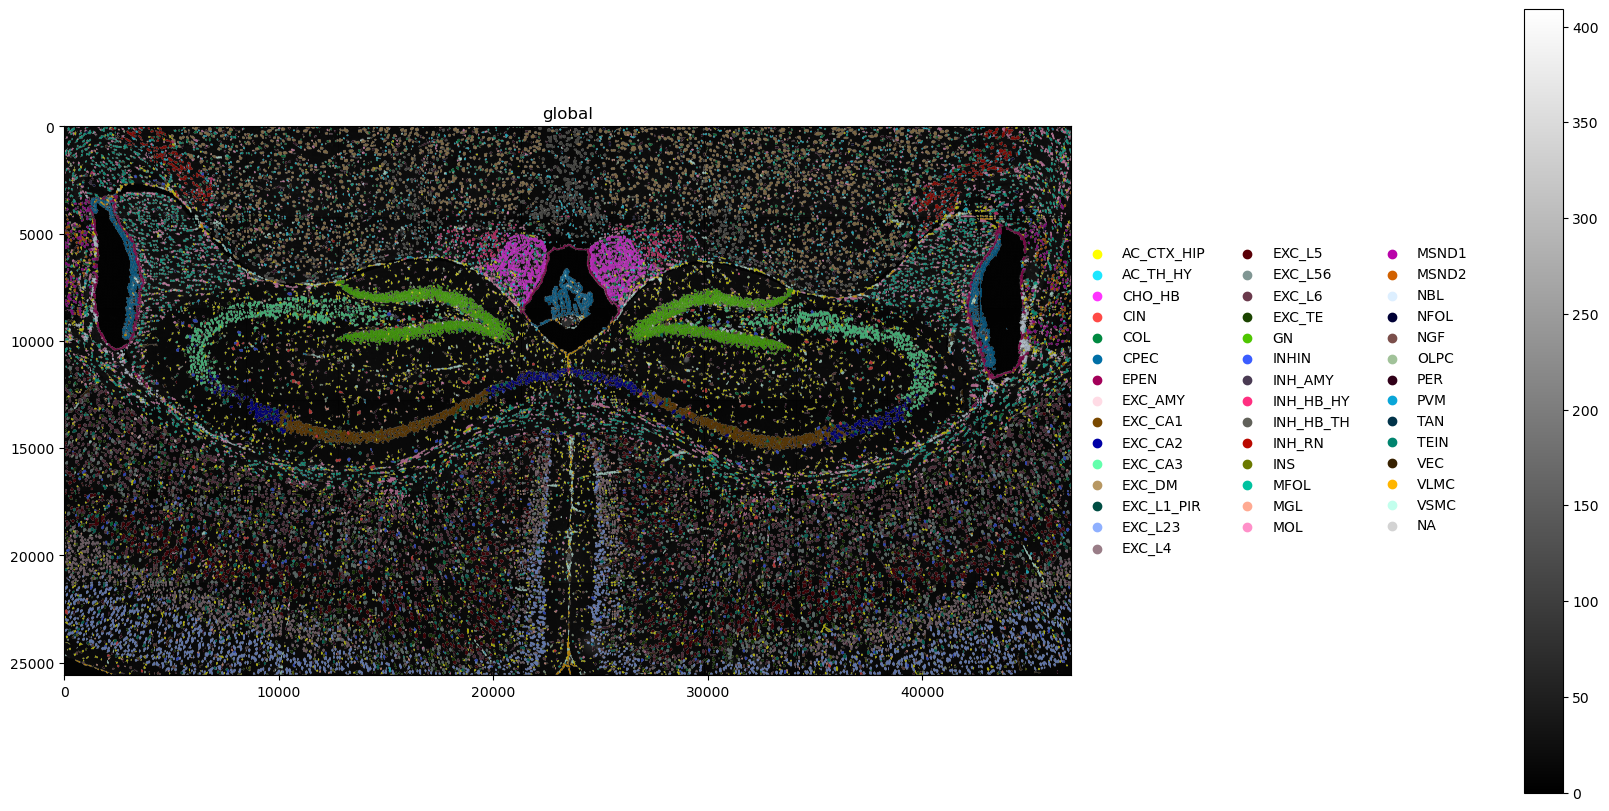

In [11]:
%%time

(
    quarterbrain_sdata
    .pl.render_images(channel="DNA", scale="scale4", cmap="gray")
    .pl.render_labels(scale="scale4", color="cluster")
    .pl.show(figsize=(16, 8))
)

In [12]:
quarterbrain_sdata.write(data_dir / "quarterbrain_sdata_celltypes.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/quarterbrain_sdata_celltypes.zarr). Please   
         see the documentation of `is_self_contained()` to understand the implications of working with SpatialData 
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/quarterbrain_sdata.zarr the new file path:   
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/quarterbrain_sdata_celltypes.zarr            


### Halfbrain

In [13]:
halfbrain_sdata =  sd.read_zarr(halfbrain_path)
halfbrain_sdata

version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/l

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/halfbrain_sdata.zarr
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 59881, 46914), (5, 29940, 23457), (5, 14970, 11728), (5, 7485, 5864), (5, 3742, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (59881, 46914), (29940, 23457), (14970, 11728), (7485, 5864), (3742, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (48556, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

In [14]:
halfbrain_sdata.tables["gexp"].obs["cell_barcode"] = [f"c_2_{row['fov']}_{row['cellID']}" for _, row in halfbrain_sdata.tables["gexp"].obs.iterrows()]

halfbrain_sdata.tables["gexp"].obs.sort_values("cell_barcode")

,fov,cellID,global_cell_id,x_global_px,y_global_px,x_local_px,y_local_px,region,cell_barcode
34042,100,1,34043,-462839.333333,7964.333333,1419,4256,segmentation,c_2_100_1
34051,100,10,34052,-463962.333333,7725.333333,296,4017,segmentation,c_2_100_10
34141,100,100,34142,-460186.333333,6390.333333,4072,2682,segmentation,c_2_100_100
34142,100,101,34143,-460964.333333,6328.333333,3294,2620,segmentation,c_2_100_101
34143,100,102,34144,-461312.333333,6324.333333,2946,2616,segmentation,c_2_100_102
...,...,...,...,...,...,...,...,...,...
1227,9,95,1228,-491514.666667,-13066.333333,2602,2392,segmentation,c_2_9_95
1228,9,96,1229,-492914.666667,-13086.333333,1202,2372,segmentation,c_2_9_96
1229,9,97,1230,-490230.666667,-13094.333333,3886,2364,segmentation,c_2_9_97
1230,9,98,1231,-490334.666667,-13106.333333,3782,2352,segmentation,c_2_9_98


In [15]:
halfbrain_sdata.tables["gexp"].obs = halfbrain_sdata.tables["gexp"].obs.merge(celltypes_halfbrain, on="cell_barcode", how="left")
halfbrain_sdata.tables["gexp"].obs

,fov_x,cellID,global_cell_id,x_global_px,y_global_px,x_local_px,y_local_px,region,cell_barcode,cluster,cluster_long,tissue,run_tissue,fov_y,x_fov_px,y_fov_px
0,1,1,1,-494130.333333,10610.000000,4253,4135,segmentation,c_2_1_1,VLMC,Vascular_leptomeningeal_cells,Half,Run1000_S1_Half,1.0,4222.0,190.0
1,1,2,2,-494171.333333,10482.000000,4212,4007,segmentation,c_2_1_2,VLMC,Vascular_leptomeningeal_cells,Half,Run1000_S1_Half,1.0,4182.0,318.0
2,1,3,3,-496189.333333,10399.000000,2194,3924,segmentation,c_2_1_3,OLPC,Oligodendrocytes_precursor_cells,Half,Run1000_S1_Half,1.0,2156.0,392.0
3,1,4,4,-494274.333333,10162.000000,4109,3687,segmentation,c_2_1_4,VLMC,Vascular_leptomeningeal_cells,Half,Run1000_S1_Half,1.0,4108.0,648.0
4,1,5,5,-494197.333333,10047.000000,4186,3572,segmentation,c_2_1_5,VSMC,Vascular_smooth_muscle_cells,Half,Run1000_S1_Half,1.0,4162.0,750.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48551,130,311,48552,-454963.000000,-21511.666667,762,1630,segmentation,c_2_130_311,AC_TH_HY,Astrocytes_Thalamus_Hypothalamus,Half,Run1000_S1_Half,130.0,748.0,2668.0
48552,130,312,48553,-454309.000000,-21725.666667,1416,1416,segmentation,c_2_130_312,SER,Serotonergic_neurons,Half,Run1000_S1_Half,130.0,1407.0,2872.0
48553,130,313,48554,-454273.000000,-22201.666667,1452,940,segmentation,c_2_130_313,TAN,Tanycytes,Half,Run1000_S1_Half,130.0,1466.0,3373.0
48554,130,314,48555,-454322.000000,-22224.666667,1403,917,segmentation,c_2_130_314,TAN,Tanycytes,Half,Run1000_S1_Half,130.0,1398.0,3385.0


In [16]:
for cat_col in ["cluster", "cluster_long"]:
    halfbrain_sdata.tables["gexp"].obs[cat_col] = pd.Categorical(halfbrain_sdata.tables["gexp"].obs[cat_col])

halfbrain_sdata.tables["gexp"].obs

,fov_x,cellID,global_cell_id,x_global_px,y_global_px,x_local_px,y_local_px,region,cell_barcode,cluster,cluster_long,tissue,run_tissue,fov_y,x_fov_px,y_fov_px
0,1,1,1,-494130.333333,10610.000000,4253,4135,segmentation,c_2_1_1,VLMC,Vascular_leptomeningeal_cells,Half,Run1000_S1_Half,1.0,4222.0,190.0
1,1,2,2,-494171.333333,10482.000000,4212,4007,segmentation,c_2_1_2,VLMC,Vascular_leptomeningeal_cells,Half,Run1000_S1_Half,1.0,4182.0,318.0
2,1,3,3,-496189.333333,10399.000000,2194,3924,segmentation,c_2_1_3,OLPC,Oligodendrocytes_precursor_cells,Half,Run1000_S1_Half,1.0,2156.0,392.0
3,1,4,4,-494274.333333,10162.000000,4109,3687,segmentation,c_2_1_4,VLMC,Vascular_leptomeningeal_cells,Half,Run1000_S1_Half,1.0,4108.0,648.0
4,1,5,5,-494197.333333,10047.000000,4186,3572,segmentation,c_2_1_5,VSMC,Vascular_smooth_muscle_cells,Half,Run1000_S1_Half,1.0,4162.0,750.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48551,130,311,48552,-454963.000000,-21511.666667,762,1630,segmentation,c_2_130_311,AC_TH_HY,Astrocytes_Thalamus_Hypothalamus,Half,Run1000_S1_Half,130.0,748.0,2668.0
48552,130,312,48553,-454309.000000,-21725.666667,1416,1416,segmentation,c_2_130_312,SER,Serotonergic_neurons,Half,Run1000_S1_Half,130.0,1407.0,2872.0
48553,130,313,48554,-454273.000000,-22201.666667,1452,940,segmentation,c_2_130_313,TAN,Tanycytes,Half,Run1000_S1_Half,130.0,1466.0,3373.0
48554,130,314,48555,-454322.000000,-22224.666667,1403,917,segmentation,c_2_130_314,TAN,Tanycytes,Half,Run1000_S1_Half,130.0,1398.0,3385.0


In [17]:
num_cols = halfbrain_sdata.tables["gexp"].obs.select_dtypes(include="number").columns
halfbrain_sdata.tables["gexp"].obs[num_cols] = halfbrain_sdata.tables["gexp"].obs[num_cols].fillna(99999999)

str_cols = halfbrain_sdata.tables["gexp"].obs.select_dtypes(include="object").columns
halfbrain_sdata.tables["gexp"].obs[str_cols] = halfbrain_sdata.tables["gexp"].obs[str_cols].fillna("")

INFO     Rasterizing image for faster rendering.                                                                   


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:798: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


CPU times: user 2min 26s, sys: 10.6 s, total: 2min 36s
Wall time: 27.3 s


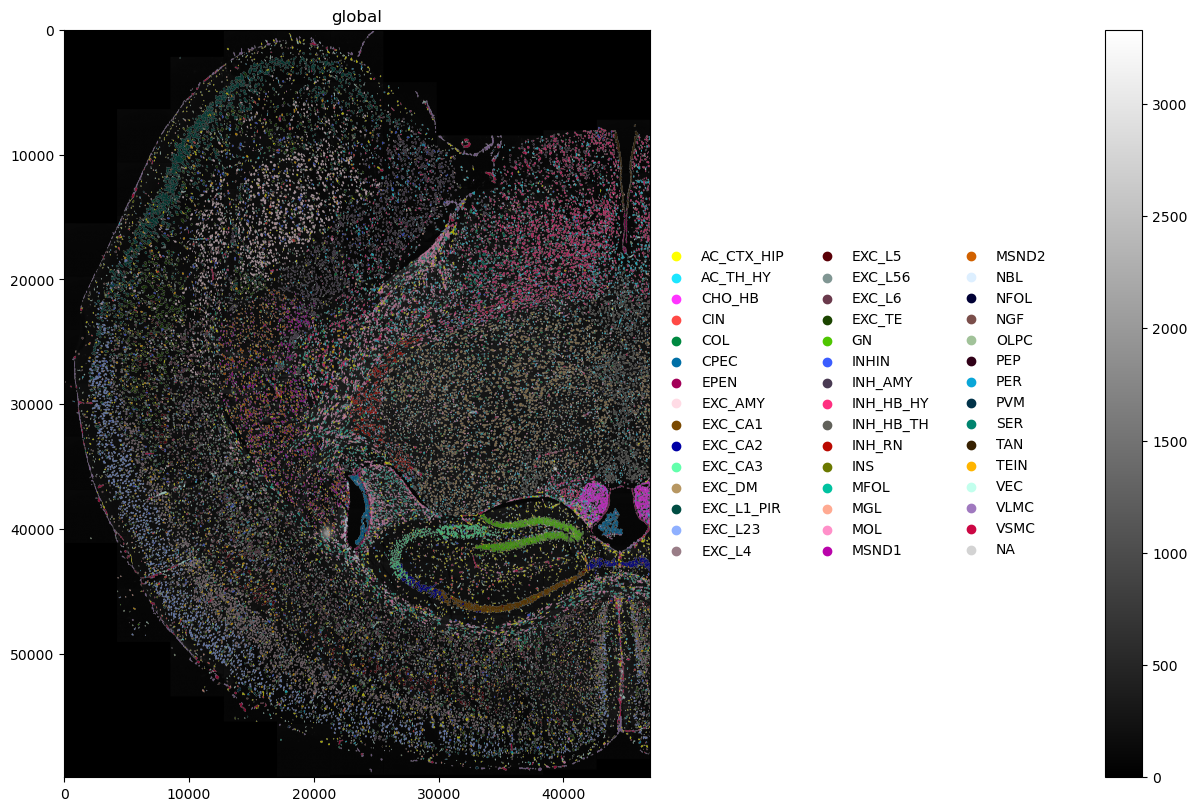

In [18]:
%%time

(
    halfbrain_sdata
    .pl.render_images(channel="DNA", scale="scale4", cmap="gray")
    .pl.render_labels(scale="scale4", color="cluster")
    .pl.show(figsize=(16, 8))
)

In [19]:
halfbrain_sdata.write(data_dir / "halfbrain_sdata_celltypes.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/halfbrain_sdata_celltypes.zarr). Please see  
         the documentation of `is_self_contained()` to understand the implications of working with SpatialData     
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/halfbrain_sdata.zarr the new file path:      
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/halfbrain_sdata_celltypes.zarr               
